# Day 5 lecture: Financial modelling and spreadsheet simulation

<p class="lead">
Every business plan rests on numbers nobody knows for sure: how many customers will come, what supplies will cost. This lecture shows how to build a clear financial model in Excel, explore it with what-if tables and scenarios, replace single guesses with random inputs in a Monte Carlo simulation, and turn thousands of simulated outcomes into risk measures a manager can act on. Python checks every idea along the way.
</p>

Open this notebook in JupyterLab from the course folder and run each cell from top to bottom with **Shift + Enter**. Keep **Microsoft Excel** open next to it: most parts end with steps to do in Excel.

---

## Recap quiz

Before we start, answer the closing quizzes at the end of yesterday's lectures on [predictive analytics and regression](D4_lecture_predictive_regression.md) and [data mining with text features](D4_lecture_data_mining_text_features.md). Write short answers; we discuss them together.

---

## What you will be able to do

1. Lay out a **financial model** with separate inputs, calculations and outputs, and follow good spreadsheet practice.
2. Run **what-if analysis** in Excel: one-way and two-way **Data Tables**, **Goal Seek** and the **Scenario Manager**.
3. Generate random inputs in Excel with `RAND()`, `RANDBETWEEN()` and `NORM.INV(RAND(), mean, sd)`, and explain how they work.
4. Build a **Monte Carlo simulation** in Excel and check it with numpy.
5. Summarise a simulation with **risk measures**: expected value, spread, probability of loss, percentiles and the average of the worst cases.
6. Explain why the **profit at average inputs** is not the **average profit** (the flaw of averages), and how many trials a simulation needs.
7. Compare two decisions under uncertainty and report the result honestly.

**Reading:** Wall Street Prep (n.d.), *Financial modeling guide*; Workday (n.d.), *Financial forecasting in Excel made easy*.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. **Check your understanding** boxes are short questions to answer in your own words. **In Excel** boxes are numbered steps to do on your computer.

> **Practice workbook**
>
> `data/leafline_simulation_practice.xlsx`, in the course folder, holds the model from this lecture, ready-made: a **Model** sheet, a frame for a Data Table, and a **Simulation** sheet with 1,000 trials. Build the model yourself first (Part 2); use the workbook to check your work or to catch up.

| Part | Topic |
|---|---|
| 1 | What a financial model is |
| 2 | The case: a new LeafLine Tea branch |
| 3 | What-if analysis: Data Tables and Goal Seek |
| 4 | Scenarios |
| 5 | Random inputs in Excel and Python |
| 6 | Monte Carlo simulation |
| 7 | Risk measures |
| 8 | How many trials? |
| 9 | The flaw of averages |
| 10 | Comparing two decisions |
| 11 | Reporting a simulation |

---

## Part 1: What a financial model is

A **financial model** is a set of linked calculations that turns **assumptions** about the business into **financial results**: revenue, costs, profit, cash. Managers use it to answer "what happens if…?" before they commit money.

| Layer | Contents | Example |
|---|---|---|
| **Inputs** (assumptions) | Numbers someone must estimate or decide | Cups sold per year, price per cup, rent |
| **Calculations** | Formulas that link inputs | Revenue = cups × price |
| **Outputs** | The results decisions depend on | Profit, break-even point |

A model is **deterministic** when each input has one value: it gives one answer. A **simulation** model lets uncertain inputs vary at random and gives a **distribution** of answers.

### Good spreadsheet practice

| Rule | Why |
|---|---|
| Put every input in its **own labelled cell**, in one place, and colour input cells (for example blue) | Anyone can see and change the assumptions |
| **Never type a number inside a formula**: refer to the input cell | One change updates the whole model; no hidden assumptions |
| Use **absolute references** (`$B$5`) for inputs that formulas copied down or across must keep | Copied formulas still point at the right input |
| Work **left to right, top to bottom**: inputs, then calculations, then outputs | The model reads like a story |
| Write the **units** in the label (per cup, per year) | Avoids mixing months and years, or cups and cartons |
| Add **checks** (for example, cups sold never exceed capacity) | Errors are caught early |

The setup cell loads the libraries. Everything here uses numpy, pandas and matplotlib; `statistics.NormalDist` comes with Python itself.

In [1]:
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY = "#c9c7c1"
INK = "#55534e"
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
pd.set_option("display.width", 120)

---

## Part 2: The case: a new LeafLine Tea branch

> **About the case**
>
> LeafLine Tea is the **synthetic** milk-tea chain from the Day 3 text-mining lecture. All numbers are invented for teaching. Amounts are in neutral **currency units**.

LeafLine Tea is deciding whether to open a new branch. The finance team's first-year assumptions:

| Input | Base value | Unit |
|---|---|---|
| Expected demand | 60,000 | cups per year |
| Price | 18 | currency units per cup |
| Variable cost (tea, milk, cups, packaging) | 7.5 | currency units per cup |
| Fixed costs (rent, staff, equipment) | 500,000 | currency units per year |
| Capacity | 75,000 | cups per year the branch can make |

The calculations:

1. **Cups sold** = the smaller of demand and capacity
2. **Revenue** = cups sold × price
3. **Variable costs** = cups sold × variable cost per cup
4. **Profit** = revenue − variable costs − fixed costs
5. **Break-even demand** = fixed costs ÷ (price − variable cost per cup): the cups needed for zero profit. Price − variable cost is the **contribution margin** per cup.

In [2]:
BASE = {"demand": 60_000, "price": 18.0, "variable_cost": 7.5, "fixed_costs": 500_000, "capacity": 75_000}


def profit(demand, price, variable_cost, fixed_costs, capacity):
    """Year-1 profit of the branch. Works on single numbers and on whole numpy arrays."""
    cups_sold = np.minimum(demand, capacity)
    return cups_sold * (price - variable_cost) - fixed_costs


base_profit = profit(**BASE)
break_even = BASE["fixed_costs"] / (BASE["price"] - BASE["variable_cost"])
print(f"Base-case profit:   {base_profit:,.0f} currency units")
print(f"Break-even demand:  {break_even:,.0f} cups per year")
print(f"Safety margin:      demand can fall {1 - break_even / BASE['demand']:.0%} below the base case before a loss")

Base-case profit:   130,000 currency units
Break-even demand:  47,619 cups per year
Safety margin:      demand can fall 21% below the base case before a loss


> **In Excel: build the base model** (about 10 minutes)
>
> 1. Open a blank workbook. Rename *Sheet1* to **Model** (double-click the tab).
> 2. In **A4:A8** type the five input labels from the table above; in **B4:B8** type the base values. Fill B4:B8 blue (**Home → Fill Color**).
> 3. In **D4:D8** type the labels *Cups sold*, *Revenue*, *Variable costs*, *Profit*, *Break-even demand*.
> 4. In **E4** type `=MIN(B4,B8)`; in **E5** `=E4*B5`; in **E6** `=E4*B6`; in **E7** `=E5-E6-B7`; in **E8** `=B7/(B5-B6)`.
> 5. Format money cells with **Home → Number Format → Number** and the thousands separator.
> 6. Check: E7 and E8 must match the Python output above.

---

## Part 3: What-if analysis: Data Tables and Goal Seek

**What-if analysis** changes inputs and watches the outputs. Its simplest form is a **one-way sensitivity table**: vary one input, hold the others at their base values.

> **Predict, then reveal**
>
> Demand falls from 60,000 to 40,000 cups. Will profit fall by a third, by about half, or by more than that?

demand (cups)   profit
       30,000 -185,000
       40,000  -80,000
       50,000   25,000
       60,000  130,000
       70,000  235,000
       80,000  287,500
       90,000  287,500


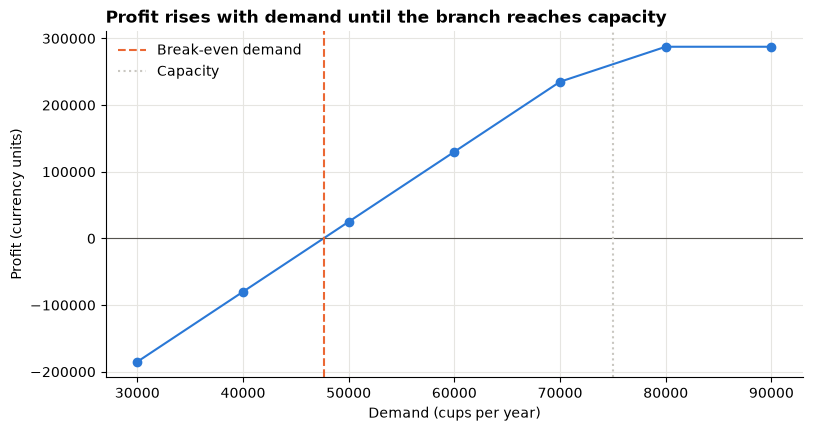

In [3]:
demands = np.arange(30_000, 90_001, 10_000)
one_way = pd.DataFrame({"demand (cups)": demands,
                        "profit": profit(demands, BASE["price"], BASE["variable_cost"],
                                         BASE["fixed_costs"], BASE["capacity"])})
print(one_way.to_string(index=False, formatters={"profit": "{:,.0f}".format, "demand (cups)": "{:,}".format}))

fig, ax = plt.subplots()
ax.plot(one_way["demand (cups)"], one_way["profit"], marker="o", color=BLUE)
ax.axhline(0, color=INK, linewidth=0.8)
ax.axvline(break_even, color=ORANGE, linestyle="--", label="Break-even demand")
ax.axvline(BASE["capacity"], color=GREY, linestyle=":", label="Capacity")
ax.set_title("Profit rises with demand until the branch reaches capacity")
ax.set_xlabel("Demand (cups per year)")
ax.set_ylabel("Profit (currency units)")
ax.legend(frameon=False)
plt.show()

Profit falls much faster than demand, because the fixed costs do not shrink when customers stay away. This is **operating leverage**: high fixed costs make profit sensitive to volume. Beyond capacity, extra demand adds nothing.

### Two-way Data Table

A **two-way Data Table** varies two inputs at once and shows the output for every combination. Here: demand down the side, price across the top.

In [4]:
prices = np.array([14, 16, 18, 20, 22])
grid = pd.DataFrame(
    [[profit(d, p, BASE["variable_cost"], BASE["fixed_costs"], BASE["capacity"]) for p in prices] for d in demands],
    index=pd.Index(demands, name="demand"), columns=pd.Index(prices, name="price"),
)
print("Profit (currency units) by demand (rows) and price per cup (columns)")
print(grid.to_string(float_format="{:,.0f}".format))

Profit (currency units) by demand (rows) and price per cup (columns)
price        14       16       18       20      22
demand                                            
30000  -305,000 -245,000 -185,000 -125,000 -65,000
40000  -240,000 -160,000  -80,000        0  80,000
50000  -175,000  -75,000   25,000  125,000 225,000
60000  -110,000   10,000  130,000  250,000 370,000
70000   -45,000   95,000  235,000  375,000 515,000
80000   -12,500  137,500  287,500  437,500 587,500
90000   -12,500  137,500  287,500  437,500 587,500


Read the table above: which combinations make a loss? Notice that a higher price helps a lot **if demand holds**. The table cannot say whether demand would hold at a higher price; that is a question for market research or an experiment, not for the spreadsheet.

> **In Excel: two-way Data Table** (Excel calls it *Data Table*; in Chinese Excel 模拟运算表)
>
> 1. On the **Model** sheet, in **B17** type `=E7` (the output you want to see). This must be the **top-left corner** of the table.
> 2. In **C17:G17** type the prices 14, 16, 18, 20, 22 (across). In **B18:B24** type the demands 30000 to 90000 in steps of 10000 (down).
> 3. Select the whole block **B17:G24**.
> 4. **Data → What-If Analysis → Data Table…** (数据 → 模拟分析 → 模拟运算表).
> 5. **Row input cell:** `B5` (price, because the prices run along the row). **Column input cell:** `B4` (demand, because the demands run down the column). Click **OK**.
> 6. Select **C18:G24** → **Home → Conditional Formatting → Color Scales** so losses stand out.
> 7. Check: your table must match the Python output above.

> **Two traps**
>
> - **The input cells must be on the same sheet as the Data Table.** If you point to an input on another sheet, Excel refuses with "Input cell reference is not valid". Keep the table on the Model sheet, or link the inputs.
> - Data Tables recalculate every time anything changes and can make a big workbook slow. **Formulas → Calculation Options → Automatic except for Data Tables** helps; press **F9** to update.

### Goal Seek

**Goal Seek** works backwards: "which value of this input gives that output?"

> **In Excel: Goal Seek** (单变量求解)
>
> 1. **Data → What-If Analysis → Goal Seek…**
> 2. **Set cell:** `E7` (profit). **To value:** `0`. **By changing cell:** `B4` (demand). Click **OK**.
> 3. Excel finds the break-even demand. Compare it with E8, then click **Cancel** to keep the original demand.

> **Check your understanding**
>
> Use the Data Table above: at a price of 16, roughly what demand does the branch need to break even? Check with the break-even formula.

---

## Part 4: Scenarios

A **scenario** changes several inputs together to tell one consistent story. Most plans show three:

| Scenario | Story | Demand | Variable cost | Fixed costs |
|---|---|---|---|---|
| **Worst case** | A rival opens nearby; milk prices rise | 42,000 | 8.5 | 520,000 |
| **Base case** | The finance team's plan | 60,000 | 7.5 | 500,000 |
| **Best case** | Strong launch; a supplier discount | 75,000 | 6.5 | 500,000 |

In [5]:
scenarios = pd.DataFrame({
    "worst case": {"demand": 42_000, "variable_cost": 8.5, "fixed_costs": 520_000},
    "base case": {"demand": 60_000, "variable_cost": 7.5, "fixed_costs": 500_000},
    "best case": {"demand": 75_000, "variable_cost": 6.5, "fixed_costs": 500_000},
}).T
scenarios["profit"] = profit(scenarios["demand"], BASE["price"], scenarios["variable_cost"],
                             scenarios["fixed_costs"], BASE["capacity"])
print(scenarios.to_string(formatters={"demand": "{:,.0f}".format, "fixed_costs": "{:,.0f}".format,
                                      "profit": "{:,.0f}".format}))

           demand  variable_cost fixed_costs   profit
worst case 42,000            8.5     520,000 -121,000
base case  60,000            7.5     500,000  130,000
best case  75,000            6.5     500,000  362,500


> **In Excel: Scenario Manager** (方案管理器)
>
> 1. **Data → What-If Analysis → Scenario Manager… → Add**.
> 2. Name it *Worst case*. **Changing cells:** `B4,B6,B7` (hold Ctrl to pick several). Click **OK**, then type the three worst-case values. Click **OK**.
> 3. Repeat for *Base case* and *Best case*.
> 4. Click **Summary…**, choose **Scenario summary**, **Result cells:** `E7`. Excel adds a new sheet comparing the scenarios.

Scenarios are easy to explain, but they have two weaknesses:

1. They say nothing about **how likely** each story is. Is the worst case a 1-in-3 or a 1-in-1,000 event?
2. The real outcome is almost never exactly one of the three. Inputs combine in countless ways.

A simulation fixes both.

---

## Part 5: Random inputs in Excel and Python

Instead of one guess for demand, we describe it with a **probability distribution**: the range of values it could take and how likely each is.

| Distribution | Use when | Excel | numpy |
|---|---|---|---|
| **Uniform** between 0 and 1 | The building block for all others | `=RAND()` | `rng.uniform(0, 1)` |
| **Uniform** between a and b | Only a range is known; every value equally likely | `=a+(b-a)*RAND()` | `rng.uniform(a, b)` |
| **Whole numbers** between a and b | Counts, equally likely | `=RANDBETWEEN(a,b)` | `rng.integers(a, b + 1)` |
| **Normal** with mean m and standard deviation s | A typical value with symmetric uncertainty around it | `=NORM.INV(RAND(),m,s)` | `rng.normal(m, s)` |
| **Yes/no** with probability p | An event that may happen (a rival opens) | `=IF(RAND()<p,1,0)` | `rng.uniform() < p` |

For LeafLine Tea the team chooses:

- **Demand:** normal, mean 60,000 cups, standard deviation 12,000 (about two times in three, demand lands between 48,000 and 72,000).
- **Variable cost per cup:** uniform between 6 and 9 (milk and tea prices could move anywhere in that range).
- Price, fixed costs and capacity stay fixed: the company sets them.

### How `NORM.INV(RAND(), mean, sd)` works

`RAND()` gives a random **probability** between 0 and 1. `NORM.INV` turns a probability into the value with that much of the normal distribution below it. A `RAND()` of 0.5 gives the mean; 0.84 gives about mean + 1 sd; 0.025 gives about mean − 2 sd. Because `RAND()` is equally likely to land anywhere between 0 and 1, the results follow the normal shape. This is called the **inverse transform** method.

Python's `NormalDist(...).inv_cdf` is the same function as Excel's `NORM.INV`, so we can check the method directly.

In [6]:
demand_dist = NormalDist(mu=60_000, sigma=12_000)
for u in [0.025, 0.16, 0.5, 0.84, 0.975]:
    print(f"RAND() = {u:<5}  ->  NORM.INV gives {demand_dist.inv_cdf(u):>8,.0f} cups")

rng = np.random.default_rng(seed=17)
u = rng.uniform(0, 1, 10_000)                                   # 10,000 "RAND()" values
via_inverse = np.array([demand_dist.inv_cdf(x) for x in u])     # Excel's way: NORM.INV(RAND(), 60000, 12000)
direct = rng.normal(60_000, 12_000, 10_000)                     # numpy's way

print(f"\n{'':<28}{'mean':>10}{'std dev':>10}")
print(f"{'NORM.INV(RAND(), ...)':<28}{via_inverse.mean():>10,.0f}{via_inverse.std(ddof=1):>10,.0f}")
print(f"{'rng.normal(...)':<28}{direct.mean():>10,.0f}{direct.std(ddof=1):>10,.0f}")

RAND() = 0.025  ->  NORM.INV gives   36,480 cups
RAND() = 0.16   ->  NORM.INV gives   48,067 cups
RAND() = 0.5    ->  NORM.INV gives   60,000 cups
RAND() = 0.84   ->  NORM.INV gives   71,933 cups
RAND() = 0.975  ->  NORM.INV gives   83,520 cups

                                  mean   std dev
NORM.INV(RAND(), ...)           59,800    12,018
rng.normal(...)                 59,930    12,143


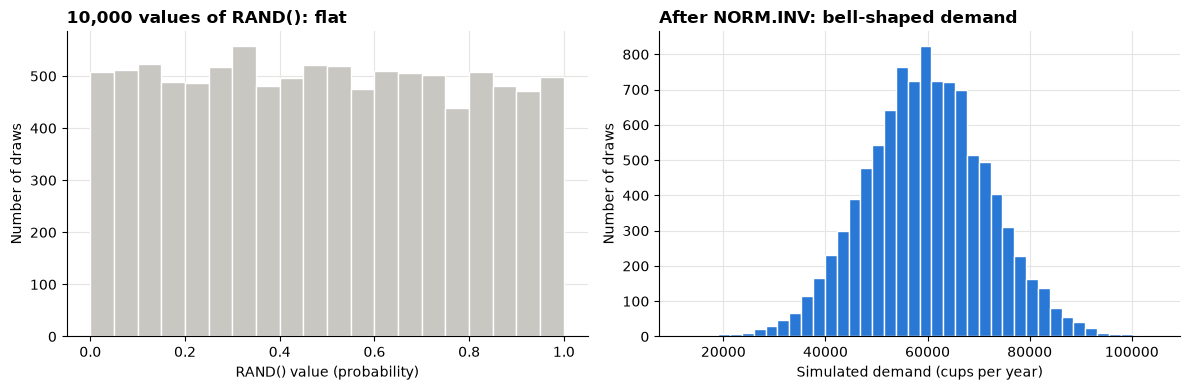

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(u, bins=20, color=GREY, edgecolor="white")
axes[0].set_title("10,000 values of RAND(): flat")
axes[0].set_xlabel("RAND() value (probability)")
axes[0].set_ylabel("Number of draws")
axes[1].hist(via_inverse, bins=40, color=BLUE, edgecolor="white")
axes[1].set_title("After NORM.INV: bell-shaped demand")
axes[1].set_xlabel("Simulated demand (cups per year)")
axes[1].set_ylabel("Number of draws")
fig.tight_layout()
plt.show()

Both methods give a mean close to 60,000 and a standard deviation close to 12,000 (output above). They are not identical, because they are different random draws.

> **Seeds: Python yes, Excel no**
>
> numpy's `default_rng(seed=…)` makes the "random" numbers repeat exactly, so everyone in the room gets the same output. Excel's `RAND()` has **no seed**: it draws new numbers every time the sheet recalculates (any edit, or **F9**). Your Excel results will differ slightly from your neighbour's and from Python. That is expected. To **freeze** one set of draws, copy the cells and use **Home → Paste → Paste Special → Values** (选择性粘贴 → 数值).

> **A normal distribution has no floor**
>
> `NORM.INV` can return negative demand when the standard deviation is large compared with the mean. Wrap it: `=MAX(0, NORM.INV(RAND(), 60000, 12000))`. Here negative values are practically impossible, but the guard costs nothing.

---

## Part 6: Monte Carlo simulation

A **Monte Carlo simulation** runs the model many times. In each **trial** it draws a random value for every uncertain input, computes the output, and records it. The collection of outputs shows the range of possible results and how likely each is.

1. Describe each uncertain input with a distribution.
2. For trial 1, draw the inputs and compute profit. Repeat for thousands of trials.
3. Summarise the profits: a histogram and risk measures.

In numpy, the profit function already works on whole arrays, so 10,000 trials take one line.

First five trials:
  demand variable_cost   profit
0 50,483          7.28   41,164
1 62,887          6.67  212,327
2 37,244          8.86 -159,717
3 76,749          6.02  398,718
4 67,660          8.95  112,118


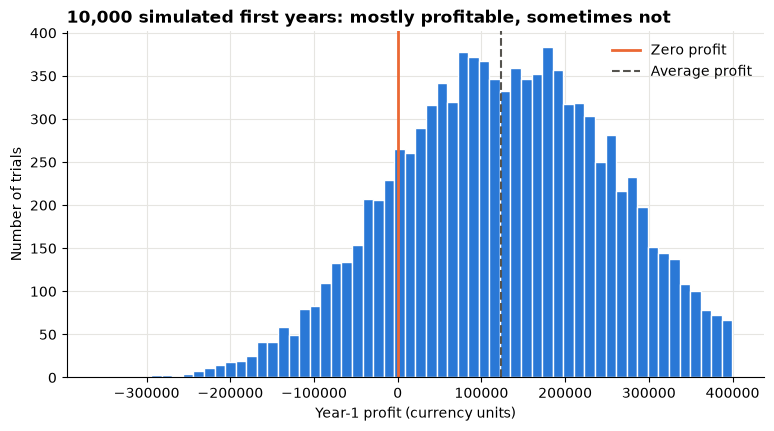

In [8]:
N = 10_000
rng = np.random.default_rng(seed=2026)
sim = pd.DataFrame({
    "demand": np.maximum(0, rng.normal(60_000, 12_000, N)),
    "variable_cost": rng.uniform(6, 9, N),
})
sim["profit"] = profit(sim["demand"], BASE["price"], sim["variable_cost"], BASE["fixed_costs"], BASE["capacity"])

print("First five trials:")
print(sim.head().to_string(formatters={"demand": "{:,.0f}".format, "variable_cost": "{:.2f}".format,
                                       "profit": "{:,.0f}".format}))

fig, ax = plt.subplots()
ax.hist(sim["profit"], bins=60, color=BLUE, edgecolor="white")
ax.axvline(0, color=ORANGE, linewidth=2, label="Zero profit")
ax.axvline(sim["profit"].mean(), color=INK, linestyle="--", label="Average profit")
ax.set_title("10,000 simulated first years: mostly profitable, sometimes not")
ax.set_xlabel("Year-1 profit (currency units)")
ax.set_ylabel("Number of trials")
ax.legend(frameon=False)
plt.show()

The histogram is not a perfect bell: its right side is cut short. That is the capacity limit. When demand is high, the branch cannot sell more than 75,000 cups, so the best outcomes are capped while the bad outcomes are not.

> **In Excel: build the simulation** (about 15 minutes; the **Simulation** sheet of the practice workbook shows the finished version)
>
> 1. Add a sheet named **Simulation**. In **A1:E1** type *Trial*, *Demand*, *Variable cost per cup*, *Cups sold*, *Profit*. On the Model sheet, add the uncertainty inputs: **B11** demand standard deviation (12000), **B12** lowest cost (6), **B13** highest cost (9).
> 2. In **A2** type 1, in **A3** type 2, select both and drag the fill handle down to **A1001** (1,000 trials).
> 3. In **B2**: `=MAX(0,NORM.INV(RAND(),Model!$B$4,Model!$B$11))`
> 4. In **C2**: `=Model!$B$12+(Model!$B$13-Model!$B$12)*RAND()`
> 5. In **D2**: `=MIN(B2,Model!$B$8)`
> 6. In **E2**: `=D2*(Model!$B$5-C2)-Model!$B$7`
> 7. Select **B2:E2** and double-click the fill handle (the small square at the bottom right) to copy the formulas down to row 1001. The `$` signs keep every formula pointing at the same inputs.
> 8. Select **E2:E1001 → Insert → Charts → Histogram** (插入 → 图表 → 直方图).
> 9. Press **F9** a few times: the histogram moves a little each time. That is the simulation working.

---

## Part 7: Risk measures

A histogram is the full picture. Managers also need a few numbers.

| Measure | Question it answers | Excel (profits in E2:E1001) | pandas |
|---|---|---|---|
| **Expected profit** | What do we get on average? | `=AVERAGE(E2:E1001)` | `.mean()` |
| **Standard deviation** | How spread out are the outcomes? | `=STDEV.S(E2:E1001)` | `.std()` |
| **Minimum, maximum** | The extremes seen in this run | `=MIN(…)`, `=MAX(…)` | `.min()`, `.max()` |
| **Probability of a loss** | How often do we lose money? | `=COUNTIF(E2:E1001,"<0")/1000` | `(profit < 0).mean()` |
| **5th percentile (P5)** | A bad year: only 1 trial in 20 is worse | `=PERCENTILE.INC(E2:E1001,0.05)` | `.quantile(0.05)` |
| **95th percentile (P95)** | A good year: only 1 in 20 is better | `=PERCENTILE.INC(E2:E1001,0.95)` | `.quantile(0.95)` |
| **Average of the worst 5%** (expected shortfall) | When things go badly, how bad on average? | `=AVERAGEIF(E2:E1001,"<="&P5cell)` | `profit[profit <= p5].mean()` |

The P5 is often called the **value at risk** at 95%: "in 95% of years, we do at least this well".

In [9]:
def risk_summary(profits):
    """Risk measures of a set of simulated profits."""
    profits = pd.Series(profits)
    p5 = profits.quantile(0.05)
    return pd.Series({
        "trials": len(profits),
        "expected profit": profits.mean(),
        "standard deviation": profits.std(),
        "minimum": profits.min(),
        "maximum": profits.max(),
        "probability of a loss": (profits < 0).mean(),
        "5th percentile (P5)": p5,
        "95th percentile (P95)": profits.quantile(0.95),
        "average of worst 5%": profits[profits <= p5].mean(),
    })


summary = risk_summary(sim["profit"])
for name, value in summary.items():
    shown = f"{value:.1%}" if name == "probability of a loss" else f"{value:,.0f}"
    print(f"{name:<24}{shown:>12}")

trials                        10,000
expected profit              123,974
standard deviation           126,834
minimum                     -357,645
maximum                      399,842
probability of a loss          17.3%
5th percentile (P5)          -87,827
95th percentile (P95)        329,550
average of worst 5%         -140,884


How to read the output above for the board:

- "On average we expect a first-year profit of about the **expected profit**, but the outcome is uncertain: in a bad year (1 in 20) profit falls to about the **P5** or below."
- "There is about a **probability of a loss** chance that the branch loses money in its first year."
- "When it does go badly, the worst 5% of years average the **average of worst 5%**."

> **Check your understanding**
>
> Two projects have the same expected profit. Project X has P5 = 50,000; project Y has P5 = −300,000. Which would a cautious owner prefer, and which number would you put first in your report?

---

## Part 8: How many trials?

A simulation **estimates** the true risk measures; more trials give a more precise estimate. To see how precise, we repeat the whole simulation 200 times with **50 trials** each, and again with **1,000** and **10,000** trials, and look at how much the estimated probability of a loss moves from run to run.

> **Predict, then reveal**
>
> With only 50 trials, could two students' estimates of the probability of a loss differ by 10 percentage points or more?

Probability of a loss, estimated in 200 separate runs
              lowest estimate highest estimate middle 95% of runs
50 trials                2.0%            34.0%      6.0% to 26.0%
1,000 trials            13.9%            19.6%     14.9% to 19.1%
10,000 trials           16.2%            18.2%     16.4% to 17.8%


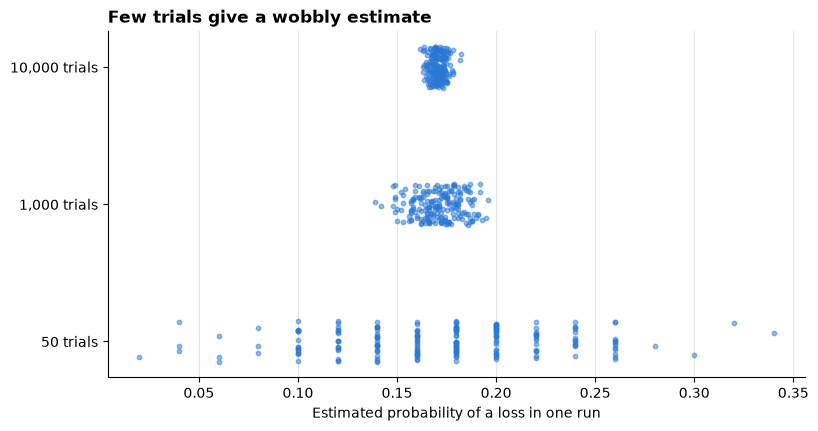

In [10]:
rng = np.random.default_rng(seed=8)
spread = {}
estimates = {}
for trials in [50, 1_000, 10_000]:
    runs = []
    for _ in range(200):
        d = np.maximum(0, rng.normal(60_000, 12_000, trials))
        c = rng.uniform(6, 9, trials)
        runs.append((profit(d, BASE["price"], c, BASE["fixed_costs"], BASE["capacity"]) < 0).mean())
    estimates[trials] = np.array(runs)
    spread[f"{trials:,} trials"] = {"lowest estimate": min(runs), "highest estimate": max(runs),
                                     "middle 95% of runs": f"{np.quantile(runs, 0.025):.1%} to {np.quantile(runs, 0.975):.1%}"}

print("Probability of a loss, estimated in 200 separate runs")
print(pd.DataFrame(spread).T.to_string(formatters={"lowest estimate": "{:.1%}".format,
                                                   "highest estimate": "{:.1%}".format}))

fig, ax = plt.subplots()
jitter = np.random.default_rng(seed=1)
for row, t in enumerate(estimates, start=1):
    ax.scatter(estimates[t], row + jitter.uniform(-0.15, 0.15, len(estimates[t])), s=10, alpha=0.5, color=BLUE)
ax.set_yticks([1, 2, 3], [f"{t:,} trials" for t in estimates])
ax.grid(axis="y", visible=False)
ax.set_title("Few trials give a wobbly estimate")
ax.set_xlabel("Estimated probability of a loss in one run")
plt.show()

With 50 trials the estimate jumps around a lot from run to run (see the range above); with 10,000 it barely moves. A rough rule: the uncertainty in an estimated probability *p* from *n* trials is about √(*p*(1 − *p*) ÷ *n*). Quadrupling the trials halves the uncertainty.

| Situation | Trials |
|---|---|
| Classroom demonstration, quick check | 50–500 |
| A decision in a normal spreadsheet | 1,000–5,000 |
| Rare events (probabilities of 1% or less) or a big decision | 10,000 or more, usually in Python or a dedicated tool |

When you press F9 in a 50-trial Excel model, expect the probability of a loss to change noticeably. Report it as an approximate figure, and use more trials before a real decision.

---

## Part 9: The flaw of averages

A tempting shortcut: put the **average** of each input into the model and read off the profit. The result is the **profit at average inputs**. Is it the same as the **average profit** over all the simulated years?

> **Predict, then reveal**
>
> Will the profit at average inputs be higher, the same, or lower than the average simulated profit?

In [11]:
at_average = profit(60_000, BASE["price"], 7.5, BASE["fixed_costs"], BASE["capacity"])
print(f"Profit at average inputs (demand 60,000, cost 7.5): {at_average:>10,.0f}")
print(f"Average simulated profit:                            {sim['profit'].mean():>10,.0f}")

no_cap = profit(sim["demand"], BASE["price"], sim["variable_cost"], BASE["fixed_costs"], np.inf)
print(f"Average simulated profit with NO capacity limit:     {no_cap.mean():>10,.0f}")

Profit at average inputs (demand 60,000, cost 7.5):    130,000
Average simulated profit:                               123,974
Average simulated profit with NO capacity limit:        130,111


Read the output above. With the capacity limit, the average simulated profit is **lower** than the profit at average inputs. In good years the branch hits capacity and cannot earn the extra profit, while in bad years it bears the full loss. Without the limit, the two numbers are close, because profit is then a straight-line function of demand.

This is the **flaw of averages**: whenever the model contains a limit, a threshold or anything non-linear (capacity, stock-outs, tax bands, minimum orders), plugging in average inputs gives the wrong average output. A simulation does not have this problem.

---

## Part 10: Comparing two decisions

LeafLine Tea has a second option: a site in a shopping mall. More customers pass by, but the rent is higher and the footfall is less predictable.

| Input | Street site (A) | Mall site (B) |
|---|---|---|
| Demand | normal, mean 60,000, sd 12,000 | normal, mean 85,000, sd 20,000 |
| Fixed costs | 500,000 | 700,000 |
| Capacity | 75,000 | 100,000 |
| Price, variable cost | 18; uniform 6 to 9 | same |

We simulate both with the **same random numbers** (the same standard-normal and uniform draws, scaled to each site). This is called **common random numbers**: differences between the two results then come from the decision, not from luck in the draws.

                      A: street site B: mall site
expected profit              123,308      164,534
standard deviation           126,722      185,781
minimum                     -328,707     -552,117
maximum                      399,999      499,999
probability of a loss          0.174        0.199
5th percentile (P5)          -86,310     -161,594
95th percentile (P95)        330,575      447,112
average of worst 5%         -139,030     -248,374


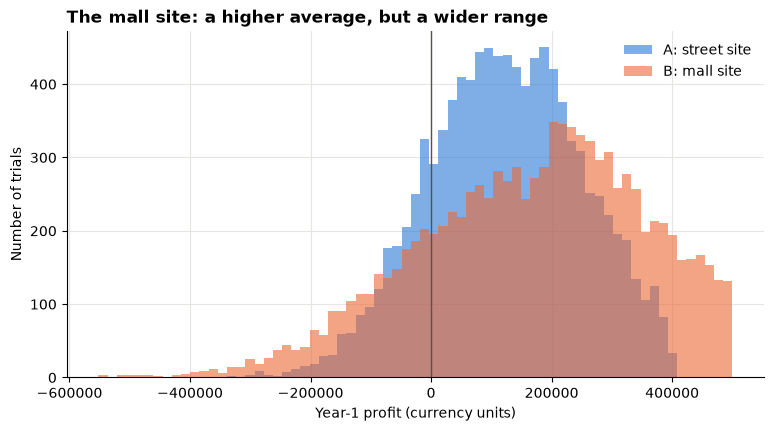

In [12]:
rng = np.random.default_rng(seed=99)
z = rng.standard_normal(N)          # shared "how good a year is it" draw
cost = rng.uniform(6, 9, N)         # shared cost draw

street = profit(np.maximum(0, 60_000 + 12_000 * z), BASE["price"], cost, 500_000, 75_000)
mall = profit(np.maximum(0, 85_000 + 20_000 * z), BASE["price"], cost, 700_000, 100_000)

comparison = pd.DataFrame({"A: street site": risk_summary(street), "B: mall site": risk_summary(mall)})
print(comparison.drop(index="trials").to_string(
    formatters={c: (lambda v: f"{v:,.3f}" if abs(v) < 1 else f"{v:,.0f}") for c in comparison.columns}))

fig, ax = plt.subplots()
bins = np.linspace(min(street.min(), mall.min()), max(street.max(), mall.max()), 70)
ax.hist(street, bins=bins, alpha=0.6, color=BLUE, label="A: street site")
ax.hist(mall, bins=bins, alpha=0.6, color=ORANGE, label="B: mall site")
ax.axvline(0, color=INK, linewidth=1)
ax.set_title("The mall site: a higher average, but a wider range")
ax.set_xlabel("Year-1 profit (currency units)")
ax.set_ylabel("Number of trials")
ax.legend(frameon=False)
plt.show()

Read the comparison table above. Neither site wins on every measure: the mall has the higher expected profit, the street site the smaller chance of a loss and the better bad year. The choice depends on the owner's **risk appetite**: a chain with cash reserves may accept more risk for a higher average; a new owner who cannot survive a bad first year should care more about the P5 and the probability of a loss.

The simulation does not make the decision. It makes the **trade-off visible**, so the decision-maker can choose knowingly.

> **Check your understanding**
>
> The mall landlord offers a lower rent of 600,000 if LeafLine signs for five years. Which line of code would you change to test this, and which two measures would you compare first?

---

## Part 11: Reporting a simulation

| Do | Don't |
|---|---|
| Give a **range** and a probability: "expected profit about …; 1 year in 20 below …; about …% chance of a loss" | Report one number as if it were certain |
| List every **assumption** and distribution in a table, with its source | Hide the inputs in formulas |
| Say how many **trials** you ran and that results vary slightly between runs | Quote results to the last unit |
| Show the **histogram** | Show only the average |
| Test what happens if a key assumption is wrong (for example a larger demand standard deviation) | Treat the distributions as facts |

> **Ethics: who carries the risk?**
>
> A plan built only on the best case can push risk onto people who did not choose it: staff who lose jobs when a branch closes, suppliers who are not paid, customers left without service. Simulating uncertainty, and reporting the bad outcomes honestly, is part of responsible decision-making. Tomorrow's lab takes this further with a supply-chain decision that has an ethical side.

---

## Summary

| Idea | One-line takeaway |
|---|---|
| Financial model | Inputs → calculations → outputs; inputs in labelled cells, never inside formulas |
| Data Table | Varies one or two inputs and shows an output for every value; input cells on the same sheet |
| Goal Seek | Finds the input value that gives a target output (for example break-even) |
| Scenarios | Consistent stories (worst, base, best); no probabilities |
| Random inputs | `RAND()`, `RANDBETWEEN()`, `NORM.INV(RAND(), mean, sd)`; Excel has no seed, numpy does |
| Monte Carlo | Draw inputs, compute the output, repeat thousands of times, summarise |
| Risk measures | Expected value, standard deviation, probability of a loss, P5/P95, average of the worst 5% |
| Number of trials | 50 trials give a rough estimate; use thousands for decisions |
| Flaw of averages | With limits or thresholds, profit at average inputs ≠ average profit |
| Comparing options | Same random numbers for both; the choice depends on risk appetite |

## Excel reference

| Task | English Excel | Chinese Excel (labels may vary slightly by version) |
|---|---|---|
| Data Table | Data → What-If Analysis → Data Table | 数据 → 模拟分析 → 模拟运算表 |
| Goal Seek | Data → What-If Analysis → Goal Seek | 数据 → 模拟分析 → 单变量求解 |
| Scenario Manager | Data → What-If Analysis → Scenario Manager | 数据 → 模拟分析 → 方案管理器 |
| Histogram chart | Insert → Charts → Histogram | 插入 → 图表 → 直方图 |
| Freeze random numbers | Copy, then Paste Special → Values | 复制，然后 选择性粘贴 → 数值 |
| Recalculate | F9 | F9 |
| Calculation options | Formulas → Calculation Options | 公式 → 计算选项 |

Function names (`RAND`, `NORM.INV`, `COUNTIF`, `PERCENTILE.INC`…) are the same in English and Chinese Excel.

---

## Closing quiz

1. Name the three layers of a financial model and give one example of each for a coffee cart.
2. Why should a formula refer to an input cell instead of containing the number itself?
3. In a two-way Data Table, the prices run across row 17 and the demands down column B. Which input cell goes in the **Row input cell** box?
4. What does `=NORM.INV(RAND(), 500, 80)` produce, and why does the result change when you press F9?
5. A simulation of 1,000 trials gives 87 trials with a loss. What is the estimated probability of a loss, and roughly how precise is it?
6. Explain the P5 of a profit distribution to a manager in one sentence.
7. A model has a capacity limit. Why is the profit at average demand higher than the average simulated profit?
8. Why is it risky, for the company and for others, to plan only on the best case?

---

## This afternoon

**Lab:** [Applied Lab 5: Predictive linear regression modelling](D5_lab_lab5_regression.md) (graded, 2%). You predict cars' fuel efficiency from their specifications with the regression workflow from yesterday's lecture.

**Tomorrow:** Applied Lab 6 builds an Excel simulation model, with a Data Table, a Monte Carlo sheet and a risk summary, for a car maker's product launch. Today's Excel steps are the preparation.